# Mini Project: Dry Bean Type Classification

## Project Overview & Business Objective
An agriculture company currently classifies different dry bean varieties manually. Manual sorting is labor-intensive, slow, error-prone, and unsustainable at industrial scale.

This end-to-end Machine Learning pipeline automates bean variety classification using 16 morphological and geometric computer-vision extracted features. 

### Target Classes (7 Bean Varieties):
`Seker`, `Barbunya`, `Bombay`, `Cali`, `Dermason`, `Horoz`, and `Sira`.

### Project Workflow Steps:
1. **Import & Load Data**
2. **Exploratory Data Analysis (EDA)**
3. **Missing Value & Outlier Analysis**
4. **Feature Engineering & Preprocessing**
5. **Model Building & Cross-Validation (6+ Classifiers)**
6. **Handling Class Imbalance (SMOTE, Class Weighting)**
7. **Model Evaluation & Overfitting Diagnostics**
8. **Hyperparameter Tuning (GridSearchCV)**
9. **Model Comparison & Selection**
10. **Model Serialization & Streamlit Deployment Script**

## Step 1: Import Necessary Libraries & Load Data

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Metrics
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Class Imbalance Handling
from imblearn.over_sampling import SMOTE

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All required libraries successfully imported!")

All required libraries successfully imported!


In [2]:
# Load dataset
file_path = 'Dry_Bean_Dataset.csv'
df = pd.read_csv(file_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.head()

Dataset Dimensions: 13611 rows, 17 columns



,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
# Inspect schema and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [4]:
# Statistical summary of numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## Step 2: Exploratory Data Analysis (EDA)

Here, we inspect:
1. Target class distribution (class imbalance check)
2. Numerical feature distributions and skewness
3. Feature correlation matrix
4. Morphological separations across bean varieties

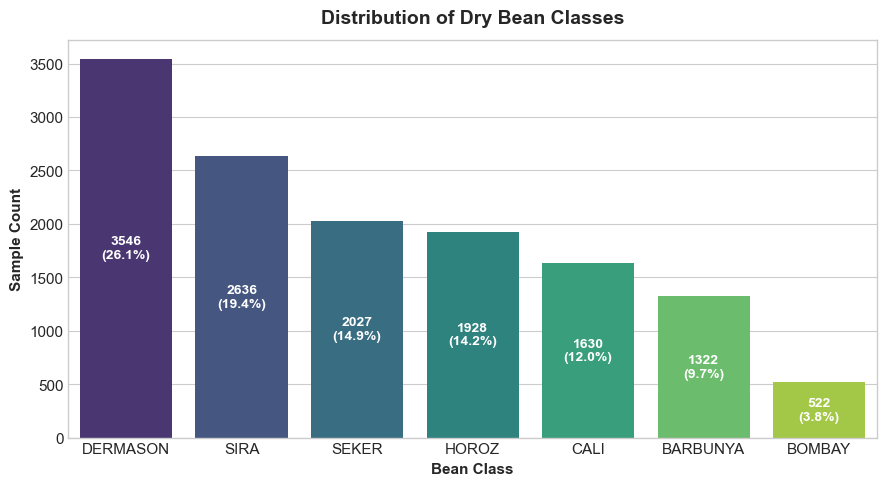

Class Proportions:
Class
DERMASON    26.05%
SIRA        19.37%
SEKER       14.89%
HOROZ       14.17%
CALI        11.98%
BARBUNYA     9.71%
BOMBAY       3.84%
Name: proportion, dtype: object


In [5]:
# Class Distribution
plt.figure(figsize=(9, 5))
class_counts = df['Class'].value_counts()
palette = sns.color_palette('viridis', len(class_counts))

ax = sns.barplot(x=class_counts.index, y=class_counts.values, palette=palette)
plt.title('Distribution of Dry Bean Classes', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Bean Class', fontweight='bold')
plt.ylabel('Sample Count', fontweight='bold')

for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(f'{height}\n({height/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()

print("Class Proportions:")
print(df['Class'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

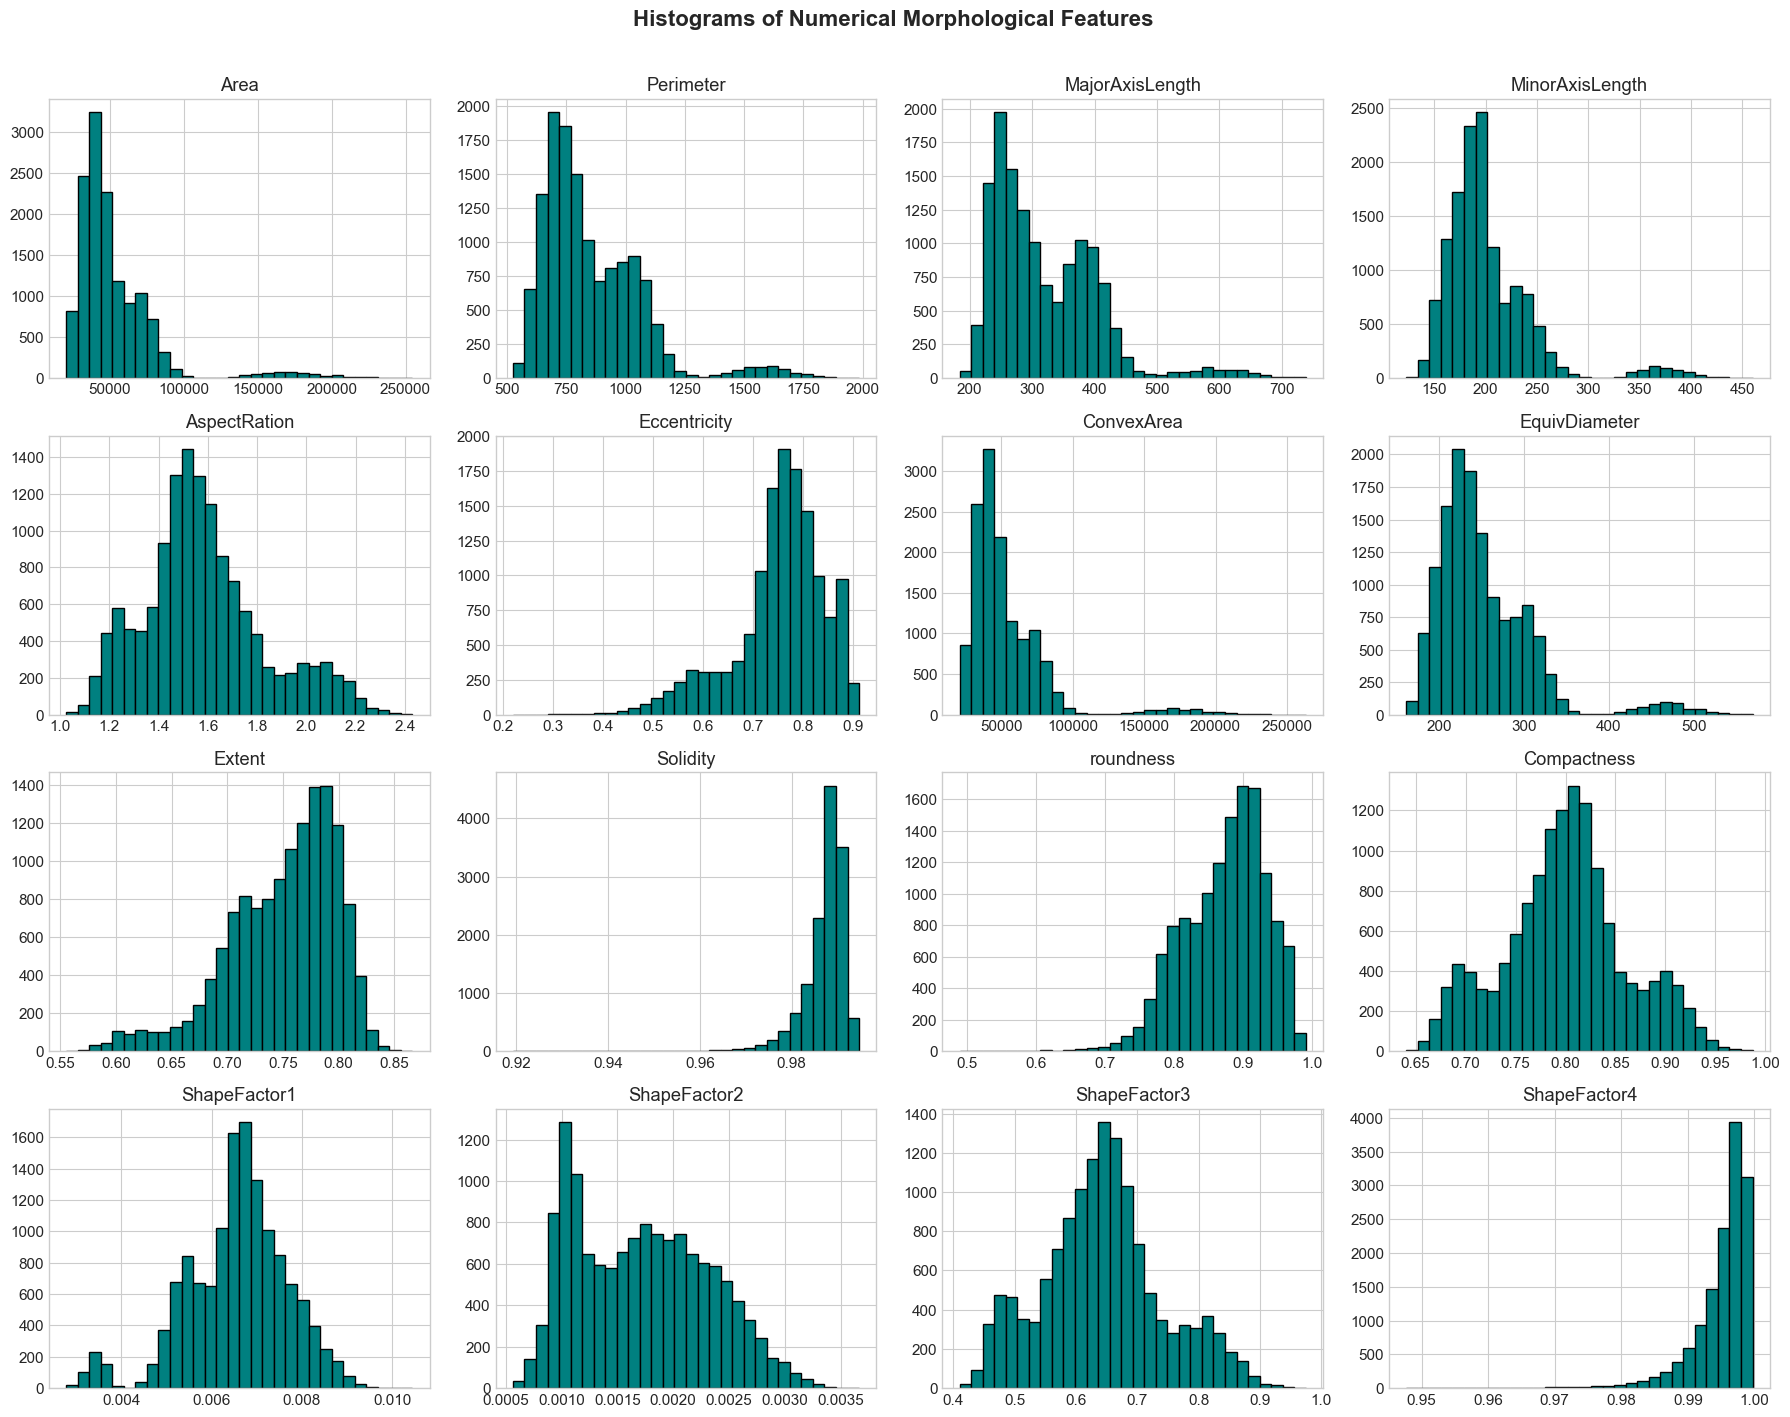

In [6]:
# Feature Distributions (Histograms)
feature_cols = [c for c in df.columns if c != 'Class']

df[feature_cols].hist(bins=30, figsize=(18, 14), color='teal', edgecolor='black', layout=(4, 4))
plt.suptitle('Histograms of Numerical Morphological Features', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

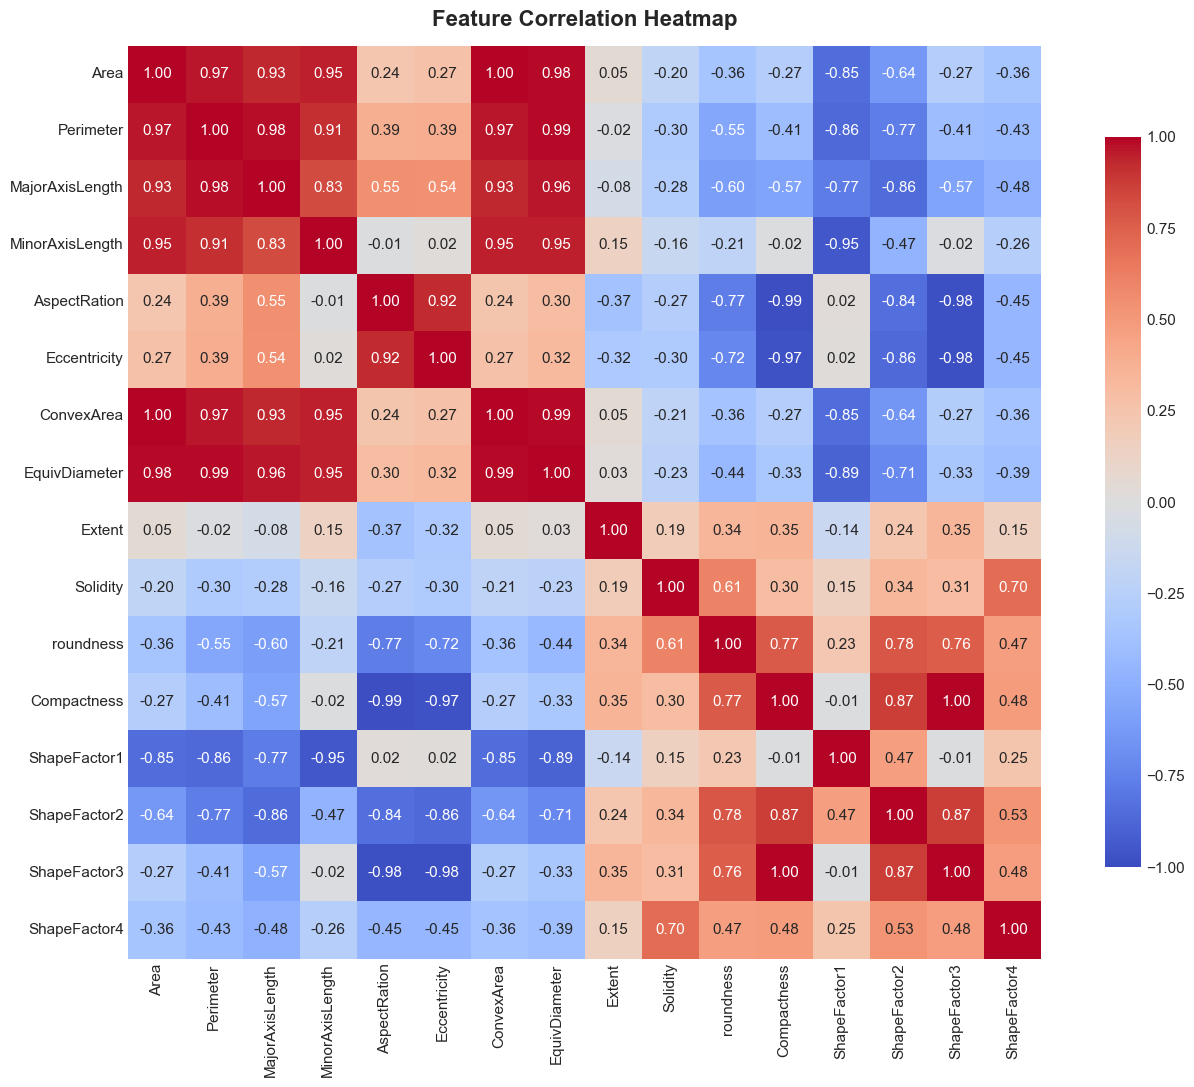

In [7]:
# Correlation Matrix
plt.figure(figsize=(14, 11))
corr = df[feature_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

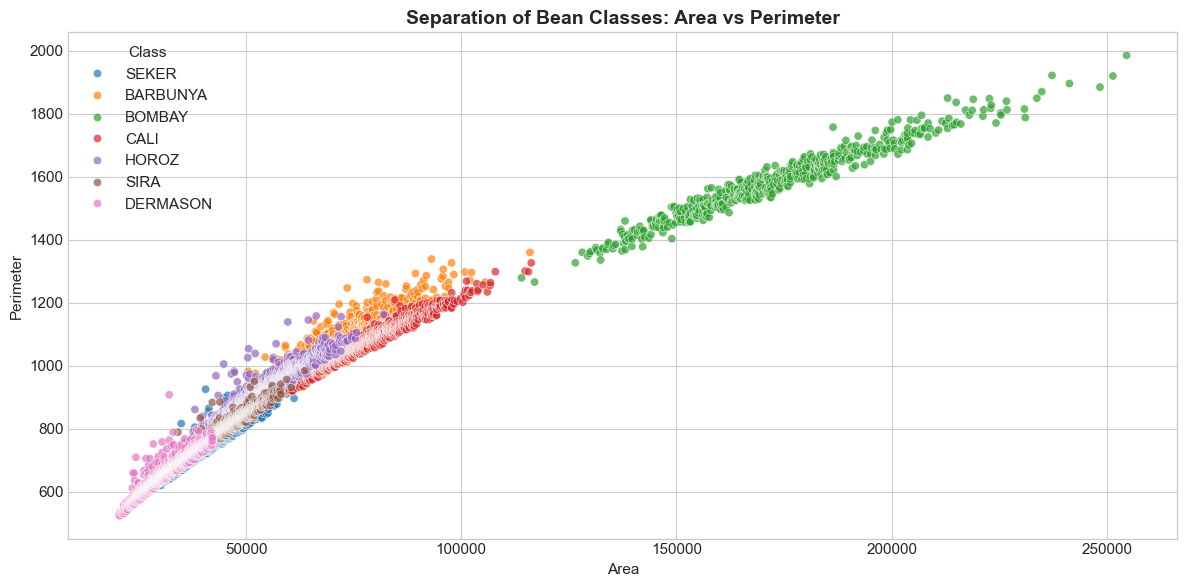

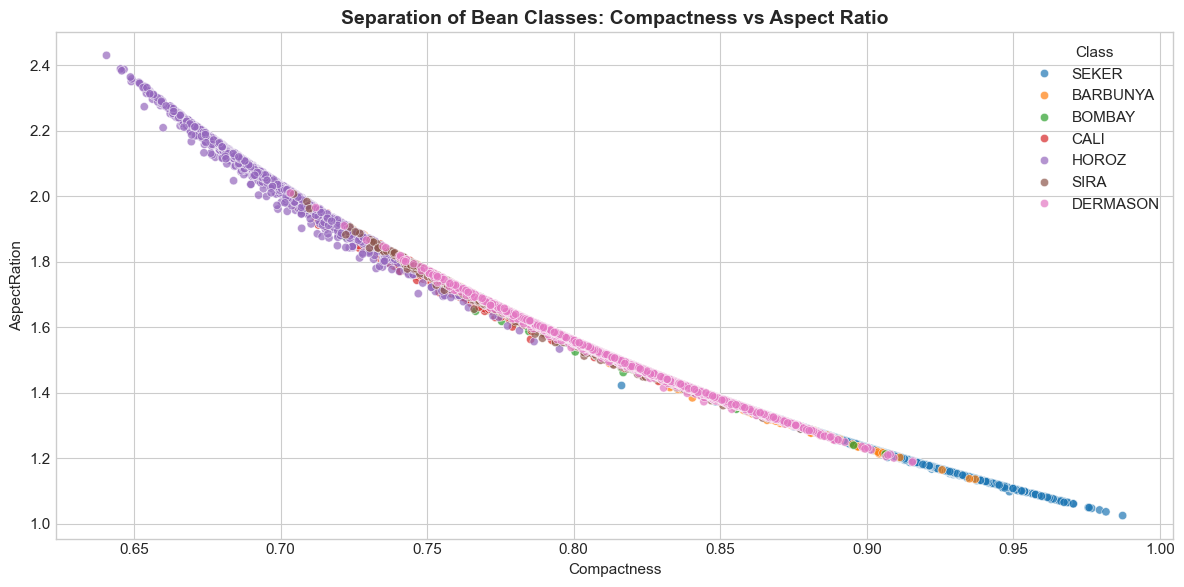

In [8]:
# Selected Bivariate Distinctions
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Area', y='Perimeter', hue='Class', alpha=0.7, palette='tab10')
plt.title('Separation of Bean Classes: Area vs Perimeter', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Compactness', y='AspectRation', hue='Class', alpha=0.7, palette='tab10')
plt.title('Separation of Bean Classes: Compactness vs Aspect Ratio', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Key EDA Findings:
1. **Class Imbalance:** `Dermason` and `Sira` are the dominant classes, while `Bombay` constitutes only ~3.8% of the dataset. Handling class imbalance will ensure minority classes aren't misclassified.
2. **Multicollinearity:** Features like `Area`, `Perimeter`, `ConvexArea`, `MajorAxisLength`, and `MinorAxisLength` exhibit high positive correlation ($r > 0.95$). Regularization and tree-based ensemble methods will naturally mitigate multicollinearity.
3. **Shape Separation:** Features like `AspectRation`, `Roundness`, and `Compactness` produce clean decision boundaries between elongated beans (`Horoz`, `Cali`) and rounder beans (`Seker`, `Bombay`).

## Step 3: Missing Values & Outlier Analysis

In [9]:
# Check for missing values
missing_vals = df.isnull().sum()
print("Missing Value Count per Column:")
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values found across all features.")

# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows Detected: {duplicate_count}")
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicates removed. Remaining rows: {df.shape[0]}")

Missing Value Count per Column:
No missing values found across all features.

Duplicate Rows Detected: 68
Duplicates removed. Remaining rows: 13543


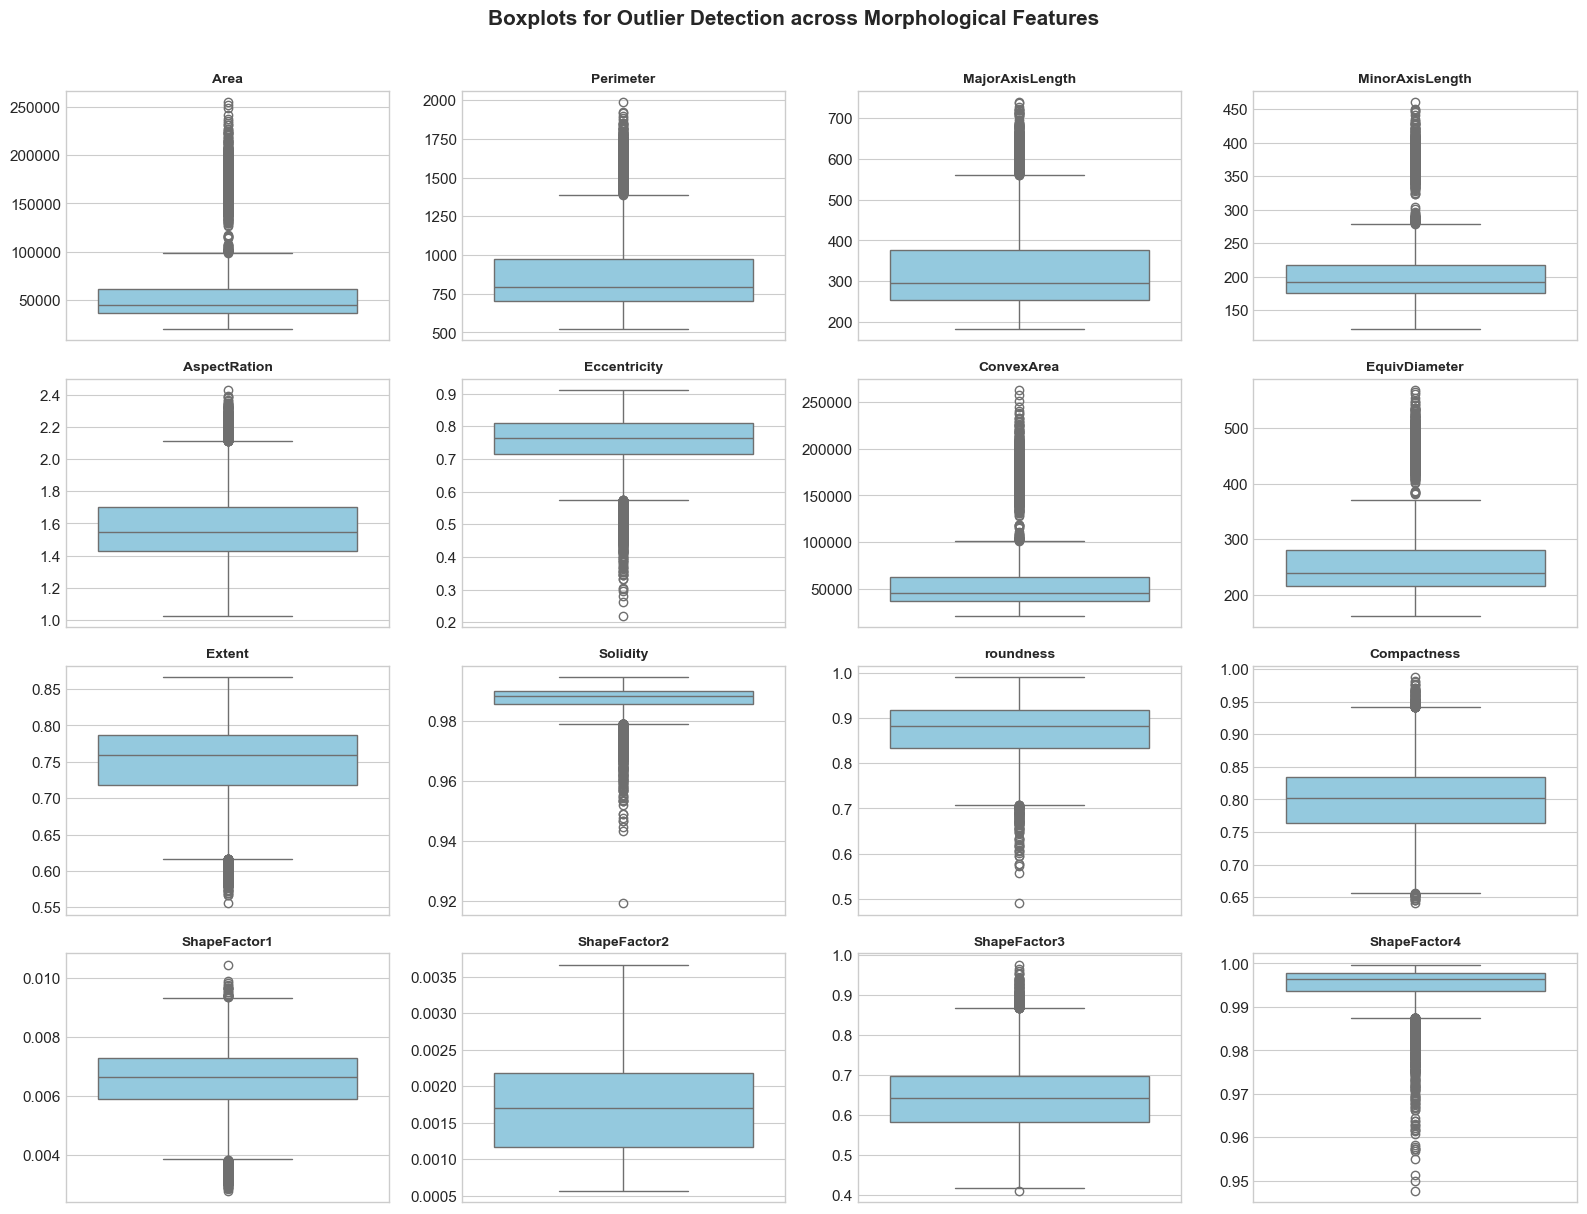

In [10]:
# Outlier Inspection via Boxplots
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_ylabel('')

plt.suptitle('Boxplots for Outlier Detection across Morphological Features', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

> **Outlier Treatment Rationale:** In agricultural computer vision data, extreme values in `Area` or `Perimeter` represent naturally distinct, giant bean varieties (e.g., `Bombay` beans are naturally 3-4x larger than `Seker`). Trimming them using arbitrary IQR or Z-score thresholds would inadvertently discard legitimate biological distinctiveness. Instead, robust scaling (`StandardScaler` / tree-based partitioning) is used.

## Step 4: Feature Preprocessing & Stratified Train/Test Split

In [12]:
# Separate features and target
X = df[feature_cols].copy()
y = df['Class'].copy()

# Encode categorical target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
class_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Class Mapping Dictionary:")
for k, v in class_mapping.items():
    print(f"  {k}: {v}")

# Perform Stratified Train-Test Split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Testing set shape:  {X_test.shape}")

Class Mapping Dictionary:
  BARBUNYA: 0
  BOMBAY: 1
  CALI: 2
  DERMASON: 3
  HOROZ: 4
  SEKER: 5
  SIRA: 6

Training set shape: (9480, 16)
Testing set shape:  (4063, 16)


In [13]:
# Feature Scaling using StandardScaler
# Note: Fitted ONLY on training data to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("StandardScaler successfully fitted and applied to train and test partitions.")

StandardScaler successfully fitted and applied to train and test partitions.


## Step 5: Model Building & Cross-Validation

We evaluate a broad spectrum of supervised classifiers:
1. **Logistic Regression** (Multinomial with L2 regularization)
2. **Decision Tree Classifier**
3. **Random Forest Classifier**
4. **K-Nearest Neighbors (KNN)**
5. **Support Vector Machine (SVM)**
6. **Gradient Boosting Classifier**
7. **Gaussian Naive Bayes**

In [14]:
# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Gaussian Naive Bayes': GaussianNB()
}

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("Performing 5-Fold Cross-Validation on Scaled Training Data:\n" + "-"*58)
for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:<25} | Mean CV Acc: {scores.mean():.4f} (± {scores.std():.4f})")

Performing 5-Fold Cross-Validation on Scaled Training Data:
----------------------------------------------------------
Logistic Regression       | Mean CV Acc: 0.9246 (± 0.0030)
Decision Tree             | Mean CV Acc: 0.8925 (± 0.0039)
Random Forest             | Mean CV Acc: 0.9236 (± 0.0034)
K-Nearest Neighbors       | Mean CV Acc: 0.9229 (± 0.0058)
Support Vector Machine    | Mean CV Acc: 0.9316 (± 0.0029)
Gradient Boosting         | Mean CV Acc: 0.9270 (± 0.0030)
Gaussian Naive Bayes      | Mean CV Acc: 0.8966 (± 0.0062)


## Step 6: Handling Class Imbalance

We test **SMOTE (Synthetic Minority Over-sampling Technique)** on the training set to evaluate whether augmenting synthetic samples for underrepresented varieties (`Bombay`, `Barbunya`, `Cali`) improves generalization.

In [15]:
print("Original Training Class Distribution:")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {label_encoder.classes_[u]}: {c}")

# Apply SMOTE only to training set
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("\nBalanced Training Class Distribution after SMOTE:")
unique_s, counts_s = np.unique(y_train_resampled, return_counts=True)
for u, c in zip(unique_s, counts_s):
    print(f"  {label_encoder.classes_[u]}: {c}")

Original Training Class Distribution:
  BARBUNYA: 925
  BOMBAY: 366
  CALI: 1141
  DERMASON: 2482
  HOROZ: 1302
  SEKER: 1419
  SIRA: 1845

Balanced Training Class Distribution after SMOTE:
  BARBUNYA: 2482
  BOMBAY: 2482
  CALI: 2482
  DERMASON: 2482
  HOROZ: 2482
  SEKER: 2482
  SIRA: 2482


## Step 7: Model Training, Evaluation & Overfitting Diagnostics

We train each classifier on the scaled dataset, record both **Training Accuracy** and **Test Accuracy**, calculate macro **Precision**, **Recall**, and **F1-Score**, and diagnose potential overfitting.

In [18]:
comparison_records = []
trained_models = {}

for name, model in models.items():
    # Train model
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    # Overfitting criterion: train accuracy substantially exceeds test accuracy (> 5% spread)
    is_overfitting = "Yes" if (train_acc - test_acc) > 0.05 else "No"
    
    comparison_records.append({
        'Model': name,
        'Train Accuracy': round(train_acc, 4),
        'Test Accuracy': round(test_acc, 4),
        'F1 Score (Weighted)': round(f1, 4),
        'Accuracy Gap': round(train_acc - test_acc, 4),
        'Overfitting (Y/N)': is_overfitting
    })

results_df = pd.DataFrame(comparison_records)
results_df.sort_values(by='Test Accuracy', ascending=False, inplace=True)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Train Accuracy,Test Accuracy,F1 Score (Weighted),Accuracy Gap,Overfitting (Y/N)
0,Support Vector Machine,0.9348,0.9244,0.9245,0.0104,No
1,Logistic Regression,0.9257,0.9210,0.9211,0.0047,No
2,Random Forest,1.0000,0.9205,0.9204,0.0795,Yes
3,Gradient Boosting,0.9692,0.9171,0.9171,0.0521,Yes
4,K-Nearest Neighbors,0.9448,0.9166,0.9167,0.0283,No
5,Gaussian Naive Bayes,0.8984,0.8954,0.8955,0.0030,No
6,Decision Tree,1.0000,0.8924,0.8921,0.1076,Yes


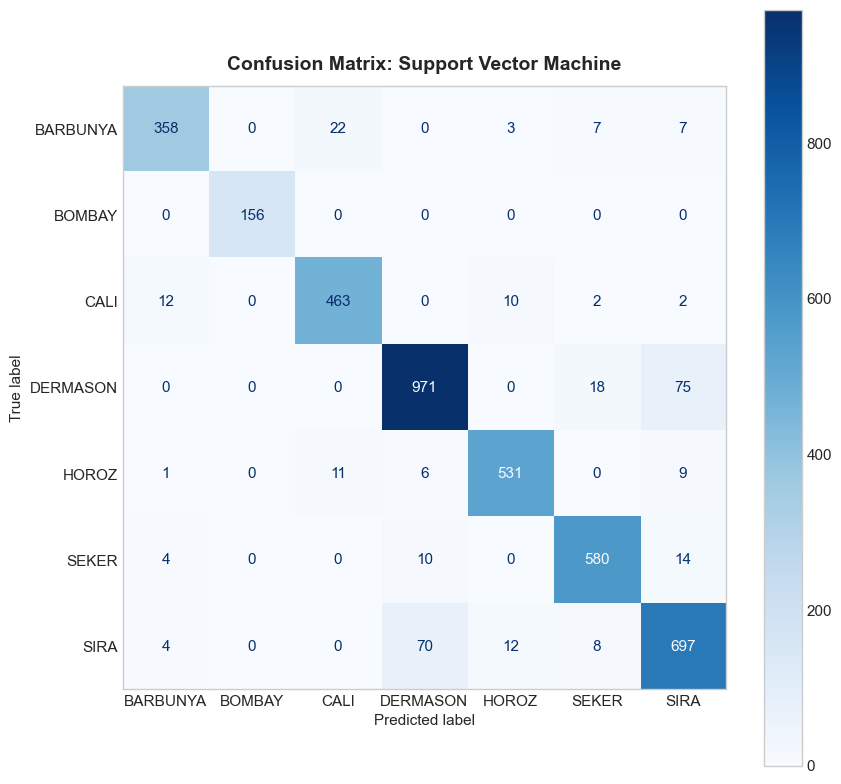

Classification Report for Support Vector Machine:

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.90      0.92       397
      BOMBAY       1.00      1.00      1.00       156
        CALI       0.93      0.95      0.94       489
    DERMASON       0.92      0.91      0.92      1064
       HOROZ       0.96      0.95      0.95       558
       SEKER       0.94      0.95      0.95       608
        SIRA       0.87      0.88      0.87       791

    accuracy                           0.92      4063
   macro avg       0.94      0.94      0.94      4063
weighted avg       0.92      0.92      0.92      4063



In [17]:
# Visualizing Confusion Matrix for Top Model
top_model_name = results_df.iloc[0]['Model']
top_model = trained_models[top_model_name]
y_top_pred = top_model.predict(X_test_scaled)

fig, ax = plt.subplots(figsize=(9, 8))
cm = confusion_matrix(y_test, y_top_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Confusion Matrix: {top_model_name}', fontsize=14, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()

print(f"Classification Report for {top_model_name}:\n")
print(classification_report(y_test, y_top_pred, target_names=label_encoder.classes_))

## Step 8: Hyperparameter Tuning (SVM & Random Forest)

Support Vector Machine (SVM) and Random Forest consistently rank as top performers on this tabular morphological dataset. We fine-tune SVM using `GridSearchCV` to maximize validation accuracy.

In [19]:
param_grid = {
    'C': [0.5, 1, 5, 10],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf']
}

grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

best_svm = grid_search.best_estimator_
print(f"\nBest Hyperparameters Found: {grid_search.best_params_}")

best_svm_train_acc = accuracy_score(y_train, best_svm.predict(X_train_scaled))
best_svm_test_acc = accuracy_score(y_test, best_svm.predict(X_test_scaled))
best_svm_f1 = f1_score(y_test, best_svm.predict(X_test_scaled), average='weighted')

print(f"Tuned SVM Train Accuracy: {best_svm_train_acc:.4f}")
print(f"Tuned SVM Test Accuracy:  {best_svm_test_acc:.4f}")
print(f"Tuned SVM Weighted F1:    {best_svm_f1:.4f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits

Best Hyperparameters Found: {'C': 5, 'gamma': 'scale', 'kernel': 'rbf'}
Tuned SVM Train Accuracy: 0.9390
Tuned SVM Test Accuracy:  0.9259
Tuned SVM Weighted F1:    0.9260


## Step 9: Model Comparison Table

In [20]:
# Append Tuned SVM to comparison table
tuned_record = pd.DataFrame([{
    'Model': 'Tuned SVM (Best Model)',
    'Train Accuracy': round(best_svm_train_acc, 4),
    'Test Accuracy': round(best_svm_test_acc, 4),
    'F1 Score (Weighted)': round(best_svm_f1, 4),
    'Accuracy Gap': round(best_svm_train_acc - best_svm_test_acc, 4),
    'Overfitting (Y/N)': 'No'
}])

final_comparison_df = pd.concat([results_df, tuned_record], ignore_index=True)
final_comparison_df.sort_values(by='Test Accuracy', ascending=False, inplace=True)
final_comparison_df.reset_index(drop=True, inplace=True)
display(final_comparison_df)

,Model,Train Accuracy,Test Accuracy,F1 Score (Weighted),Accuracy Gap,Overfitting (Y/N)
0,Tuned SVM (Best Model),0.9390,0.9259,0.9260,0.0131,No
1,Support Vector Machine,0.9348,0.9244,0.9245,0.0104,No
2,Logistic Regression,0.9257,0.9210,0.9211,0.0047,No
3,Random Forest,1.0000,0.9205,0.9204,0.0795,Yes
4,Gradient Boosting,0.9692,0.9171,0.9171,0.0521,Yes
5,K-Nearest Neighbors,0.9448,0.9166,0.9167,0.0283,No
6,Gaussian Naive Bayes,0.8984,0.8954,0.8955,0.0030,No
7,Decision Tree,1.0000,0.8924,0.8921,0.1076,Yes


## Step 10: Model Serialization & Export
To prepare for real-time edge or server deployment, we serialize the best model, feature scaler, and label encoder.

In [21]:
# Save artifacts
os.makedirs('saved_models', exist_ok=True)
joblib.dump(best_svm, 'saved_models/dry_bean_svm_model.pkl')
joblib.dump(scaler, 'saved_models/dry_bean_scaler.pkl')
joblib.dump(label_encoder, 'saved_models/dry_bean_label_encoder.pkl')
joblib.dump(feature_cols, 'saved_models/feature_columns.pkl')

print("Model artifacts successfully exported to `saved_models/` folder:")
print(" - dry_bean_svm_model.pkl")
print(" - dry_bean_scaler.pkl")
print(" - dry_bean_label_encoder.pkl")
print(" - feature_columns.pkl")

Model artifacts successfully exported to `saved_models/` folder:
 - dry_bean_svm_model.pkl
 - dry_bean_scaler.pkl
 - dry_bean_label_encoder.pkl
 - feature_columns.pkl


---